# Individual homework project 2

You will apply statistical testing and correlation analysis to the ShopNow dataset.

For each question:

1. Run the appropriate test.
2. Report the test statistic and p-value (if applicable).
3. Interpret the result in plain English.
4. Explain what it means for the business.

In [9]:
# Import modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [2]:
# Import datasets

customers = pd.read_csv("data/customers.csv")
transactions = pd.read_csv("data/transactions.csv")
sessions = pd.read_csv("data/web_sessions.csv")
campaigns = pd.read_csv("data/campaign_touchpoints.csv")

### Specific questions

Q1. Do customers from the UK spend more per transaction than customers from Germany?

In [5]:
#merge the transactions and customers DataFrames on the 'customer_id' column
merged = pd.merge(transactions, customers, on='customer_id', how='inner')

#calculating the average transaction value for UK and Germany
uk_values = (
    merged.loc[merged['country'].str.contains('UK', case=False, na=False)]
    .groupby('transaction_id')['purchase_value']
    .sum()
)
avg_per_tran_value_uk = round(uk_values.mean(), 2)

germany_values = (
    merged.loc[merged['country'].str.contains('Germany', case=False, na=False)]
    .groupby('transaction_id')['purchase_value']
    .sum()
)
avg_per_tran_value_germany = round(germany_values.mean(), 2)

#printing the values
print(f"The average transaction value for UK is: {avg_per_tran_value_uk}")
print(f"The average transaction value for Germany is: {avg_per_tran_value_germany}")

The average transaction value for UK is: 234.84
The average transaction value for Germany is: 239.03


H₀ (Null Hypothesis):
Customers from UK spend same per transaction as customers from Germany

H₁ (Alternative Hypothesis):
Customers from UK spend more per transaction than in Germany


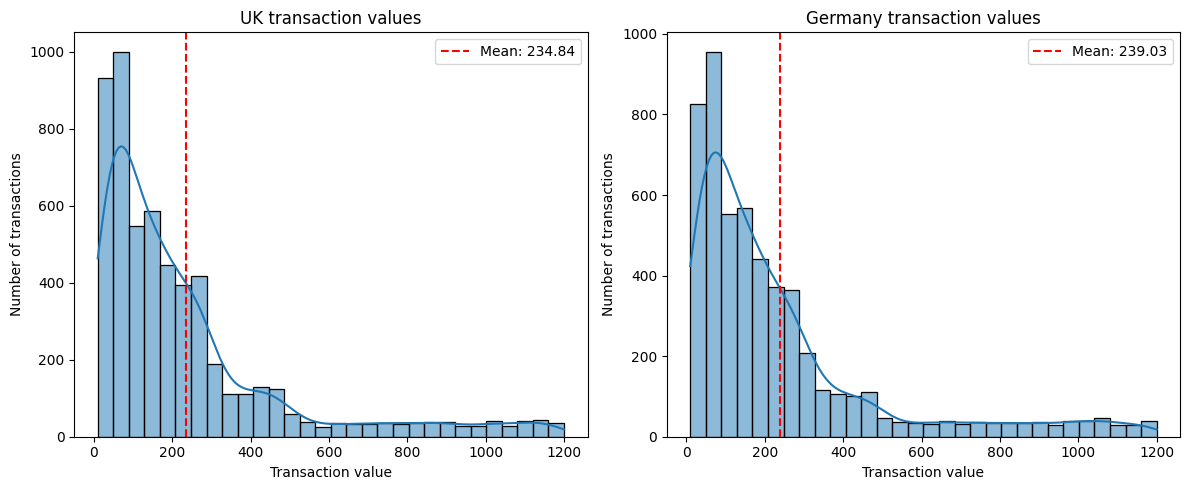

In [6]:
# plotting the average transaction values for UK and Germany
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)

for ax, values, country in zip(
    axes,
    [uk_values, germany_values],
    ['UK', 'Germany']
):
    values = values.dropna()

    sns.histplot(values, bins=30, kde=True, ax=ax)
    mean_value = values.mean()
    ax.axvline(mean_value, color='red', linestyle='--',
               label=f'Mean: {mean_value:.2f}')

    ax.set_title(f'{country} transaction values')
    ax.set_xlabel('Transaction value')
    ax.set_ylabel('Number of transactions')
    ax.legend()

plt.tight_layout()
plt.show()


In [11]:
from scipy.stats import ttest_ind

result = ttest_ind(uk_values, germany_values, equal_var=False)

print(f"UK mean: {uk_values.mean():.2f}")
print(f"Germany mean: {germany_values.mean():.2f}")
print(f"t-statistic: {result.statistic:.3f}")
print(f"p-value: {result.pvalue:.4f}")

UK mean: 234.84
Germany mean: 239.03
t-statistic: -0.861
p-value: 0.3892


The p-value is *higher* than significance level (0.05), so we fail to reject the Null hypothesis. Which means, there is 38% chance of incorrectly rejecting Null Hypothesis.

We compared average transaction values in the UK and Germany. The test did not find statistically significant evidence that UK customers spend more per transaction than customers in Germany. Based on this analysis, we can’t conclude that UK spending is higher; this also doesn’t prove the two markets spend the same. We should avoid changing country-specific pricing or strategy based on this result alone.

Q2. Do discounted purchases differ in average value from non-discounted purchases?

H₀ (Null Hypothesis):
Discounted purchases are same as Non-Discounted purchases

H₁ (Alternative Hypothesis):
Discounted purchases differ from Non-Discounted purchases


In [14]:
from scipy.stats import ttest_ind

#extracting purchase values for discounted and non-discounted purchases
discounted_purchases = transactions.loc[transactions['discount_used'] == 1, 'purchase_value'].dropna()

non_discounted_purchases = transactions.loc[transactions['discount_used'] == 0, 'purchase_value'].dropna()


#calculating means and p-value using t-test
discounted_mean = discounted_purchases.mean()
non_discounted_mean = non_discounted_purchases.mean()
result = ttest_ind(discounted_purchases,non_discounted_purchases,equal_var=False)

#printing the means, t-statistic and p-value
print("Discounted mean:", round(discounted_mean, 2))
print("Non-discounted mean:", round(non_discounted_mean, 2))
print("t-statistic:", round(result.statistic, 3))
print("p-value:", round(result.pvalue, 4))


Discounted mean: 235.61
Non-discounted mean: 234.56
t-statistic: 0.401
p-value: 0.6882


Because the p-value is 0.6882, which is greater than 0.05, we fail to reject the null hypothesis. We don’t have enough evidence to conclude that the average purchase values differ between discounted and non-discounted purchases.

Q3. Do male and female customers differ in average purchase value?

H₀ (Null Hypothesis):
Average Purchase Value is same for both male and female customers.

H₁ (Alternative Hypothesis):
Average Purchase Value is different for both male and female customers.

In [15]:
#merge the transactions and customers DataFrames on the 'customer_id' column
merged = pd.merge(transactions, customers, on='customer_id', how='inner')

#extracting the lists for male and female customers transaction values
male_values = (
    merged.loc[merged['gender'].str.contains('Male', case=False, na=False)]
    .groupby('transaction_id')['purchase_value']
    .sum()
)

female_values = (
    merged.loc[merged['gender'].str.contains('Female', case=False, na=False)]
    .groupby('transaction_id')['purchase_value']
    .sum()
)

#calculating means and p-value using t-test
avg_purchase_value_male = round(male_values.mean(), 2)
avg_purchase_value_female = round(female_values.mean(), 2)
result = ttest_ind(male_values, female_values, equal_var=False)


#printing the values
print(f"The average transaction value for male customers is: {avg_purchase_value_male}")
print(f"The average transaction value for female customers is: {avg_purchase_value_female}")
print(f"t-statistic: {result.statistic:.3f}")
print(f"p-value: {result.pvalue:.4f}")


The average transaction value for male customers is: 235.38
The average transaction value for female customers is: 235.94
t-statistic: -0.223
p-value: 0.8237


Because the p-value is 0.8237, which is greater than 0.05, we fail to reject the null hypothesis. We don’t have enough evidence to conclude that the average purchase values differ between male and female customer purchases.

Q4. Do customers acquired via email spend more than those from social channels?

H₀ (Null Hypothesis):
Email-acquired customers average spend is less than or equal to social-acquired customers average spend.

H₁ (Alternative Hypothesis):
Email-acquired customers average spend is greater than social-acquired customers average spend.

In [27]:
#merge the customers and transactions DataFrames on the 'customer_id' column
merged = pd.merge(customers, transactions, on='customer_id', how='inner')

#extracting the lists for email_acquisition and social_acquisition customers purchase values
email_acquisition_values = (
    merged.loc[merged['acquisition_channel'].str.strip().str.lower() == 'email']
    .groupby('customer_id')['purchase_value']
    .sum()
)

social_acquisition_values = (
    merged.loc[merged['acquisition_channel'].str.strip().str.lower() == 'social']
    .groupby('customer_id')['purchase_value']
    .sum()
)

#calculating means and p-value using t-test
avg_spend_value_email = round(email_acquisition_values.mean(), 2)
avg_spend_value_social = round(social_acquisition_values.mean(), 2)
result = ttest_ind(email_acquisition_values, social_acquisition_values, equal_var=False, alternative='greater')


#printing the values
#print(len(email_acquisition_values))
#print(len(social_acquisition_values))
print(f"The average spend value for email acquisition customers is: {avg_spend_value_email}")
print(f"The average spend value for social acquisition customers is: {avg_spend_value_social}")
print(f"t-statistic: {result.statistic:.3f}")
print(f"p-value: {result.pvalue:.4f}")


2199
1878
The average spend value for email acquisition customers is: 1087.17
The average spend value for social acquisition customers is: 1063.51
t-statistic: 1.039
p-value: 0.1494


For the one-sided t-test comparing total spend per customer (each customer’s purchases summed) for email versus social acquired customers, the p-value is 0.1494.

Since this is above 0.05, the result does not provide enough evidence to conclude that email-acquired customers spend more than social-acquired customers on average.

Q5. Is device type associated with conversion?

H₀ (Null Hypothesis):
Device type is not associated with conversion, they are independent.

H₁ (Alternative Hypothesis):
Device type is associated with conversion.

In [33]:
from scipy.stats import chi2_contingency

# Create a count table: device type by conversion outcome
table = pd.crosstab(sessions['device_type'],sessions['converted'])

# Run the chi-square test
result = chi2_contingency(table)

print(table)
print(f"Chi-square statistic: {result.statistic:.3f}")
print(f"p-value: {result.pvalue:.4f}")

converted        0     1
device_type             
desktop      20020  3068
mobile       20213  3042
tablet       20244  3013
Chi-square statistic: 1.150
p-value: 0.5626


Since the p-value is greater than 0.05, this test does not find statistically significant evidence of an association between device type and conversion.

Q6. Is acquisition channel associated with conversion?

H₀ (Null Hypothesis):
Acquistion channel is not associated with conversion, they are independent.

H₁ (Alternative Hypothesis):
Acquistion channel is associated with conversion.

In [35]:
from scipy.stats import chi2_contingency

merged_sessions = pd.merge(sessions, customers, on='customer_id', how='inner')

# Create a count table: acquisition channel by conversion outcome
table = pd.crosstab(merged_sessions['acquisition_channel'],merged_sessions['converted'])

# Run the chi-square test
result = chi2_contingency(table)

print(table)
print(f"Chi-square statistic: {result.statistic:.3f}")
print(f"p-value: {result.pvalue:.4f}")

converted                0     1
acquisition_channel             
Email                 1708   277
email                11817  1771
organic              11079  1673
paid_Search           1206   160
paid_search          12003  1754
referral             11563  1746
social               11545  1798
Chi-square statistic: 6.775
p-value: 0.3421


As the p-value is higher than significance value, this test does not find statistically significant evidence of an association between acquistion channel and conversion.

Q7. Is product category associated with discount usage?

H₀ (Null Hypothesis):
Product Category is not associated with Discount usage, they are independent.

H₁ (Alternative Hypothesis):
Product Category is associated with Discount usage.

In [38]:
from scipy.stats import chi2_contingency

# Create a count table: device type by conversion outcome
table = pd.crosstab(transactions['product_category'],transactions['discount_used'])

# Run the chi-square test
result = chi2_contingency(table)

print(table)
print(f"Chi-square statistic: {result.statistic:.3f}")
print(f"p-value: {result.pvalue:.4f}")

discount_used        0     1
product_category            
beauty            5305  2281
electronics       5212  2212
fashion           5326  2255
home              5210  2278
sports            5225  2279
toys              5196  2221
Chi-square statistic: 1.462
p-value: 0.9174


As the p-value is higher than significance value, this test does not find statistically significant evidence of an association between product category and Discount usage.

Q8. Is time on site correlated with purchase value?

In [46]:
from scipy.stats import pearsonr

merged = pd.merge(transactions, sessions, on='customer_id', how='inner')

correlation_matrix = merged[['purchase_value', 'time_on_site']].corr()
correlation_matrix

correlation_coefficient, p_value = pearsonr(merged["purchase_value"], merged["time_on_site"])
print(f"Correlation coefficient: {correlation_coefficient:.4f}")
print(f"p-value: {p_value:.3f}")

Correlation coefficient: 0.0002
p-value: 0.927


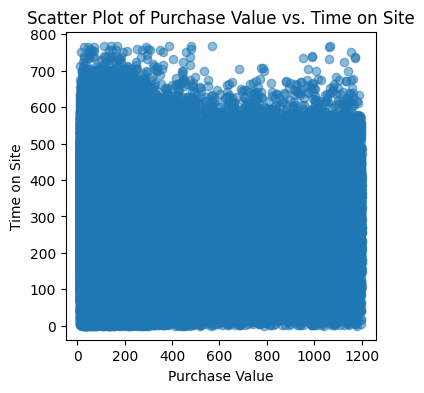

In [57]:
plt.figure(figsize=(4, 4))
plt.scatter(merged["purchase_value"], merged["time_on_site"], alpha=0.5)
plt.xlabel("Purchase Value")
plt.ylabel("Time on Site")
plt.title("Scatter Plot of Purchase Value vs. Time on Site")
plt.show()

The correlation coefficient is almost zero, so there is no significant relation between time spent on site and the purchase value. Also, the p-value is very high and does not support the claim.

Q9. Is number of pages viewed correlated with purchase value?

In [51]:
from scipy.stats import pearsonr

merged = pd.merge(transactions, sessions, on='customer_id', how='inner')

correlation_matrix = merged[['purchase_value', 'pages_viewed']].corr()
correlation_matrix

corr, p_value = pearsonr(merged["purchase_value"], merged["pages_viewed"])
print(f"Correlation coefficient: {corr:.4f}")
print(f"p-value: {p_value:.3f}")

Correlation coefficient: -0.0036
p-value: 0.044


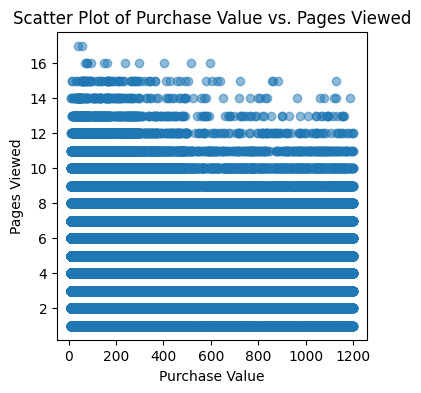

In [56]:
plt.figure(figsize=(4, 4))
plt.scatter(merged["purchase_value"], merged["pages_viewed"], alpha=0.5)
plt.xlabel("Purchase Value")
plt.ylabel("Pages Viewed")
plt.title("Scatter Plot of Purchase Value vs. Pages Viewed")
plt.show()

The p-value is below 0.05, so the test indicates a statistically significant association. But the correlation is essentially zero and slightly negative—there is no meaningful linear relationship between pages viewed and purchase value in this merged data.


Q10. Is time on site correlated with pages viewed?

In [52]:
correlation_matrix = sessions[['time_on_site', 'pages_viewed']].corr()
correlation_matrix

corr, p_value = pearsonr(sessions["time_on_site"], sessions["pages_viewed"])
print(f"Correlation coefficient: {corr:.4f}")
print(f"p-value: {p_value:.3f}")

Correlation coefficient: 0.0045
p-value: 0.229


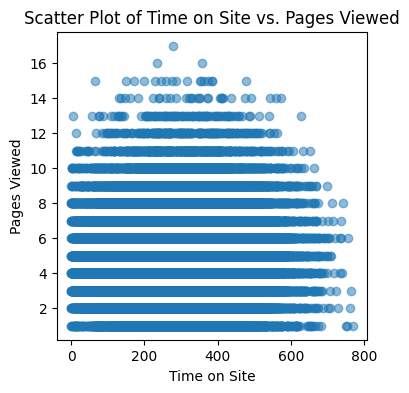

In [55]:
plt.figure(figsize=(4, 4))
plt.scatter(sessions["time_on_site"], sessions["pages_viewed"], alpha=0.5)
plt.xlabel("Time on Site")
plt.ylabel("Pages Viewed")
plt.title("Scatter Plot of Time on Site vs. Pages Viewed")
plt.show()

Correlation coefficient is close to zero and doesn't indicate strong relation between time on-site and the pages viewed in the data.The p-value is above 0.05, so there is no significant association between time on-site and pages viewed.

### Challenges

C1. Explore whether high-spending customers behave differently in terms of session time.

Define “high spending” yourself.

In [58]:
transactions['purchase_value'].describe()

count    45000.00000
mean       234.87805
std        252.98168
min         10.01000
25%         67.40000
50%        152.33500
75%        278.16250
max       1199.89000
Name: purchase_value, dtype: float64

**High spending customers** - Considering the top 25% customers based on their total purchase value. So grouping the purchase value by customer ID, calculating the sum and setting the cut off value at 75% percentile to derive this top spender's list.

Calculations done to explore high spending customers and their association with session times :

1) Total Purchase Value - grouped by customer_id and calculated the sum
2) Average session time - grouped by customer_id and calculated the mean

In [60]:
customer_spend = transactions.groupby('customer_id')['purchase_value'].sum()

# Identify high-spending customers based on the 75th percentile - defining the cutoff value for high spenders
high_spend_cutoff = customer_spend.quantile(0.75)

# Filter customers who spent above the cutoff
high_spending_customers = customer_spend[customer_spend >= high_spend_cutoff]

print(f"High-spend cutoff: {high_spend_cutoff:.2f}")
print(f"Number of high-spending customers: {len(high_spending_customers)}")


High-spend cutoff: 1493.18
Number of high-spending customers: 2470


In [68]:
from scipy.stats import pearsonr

# Total purchase value per customer
customer_spend = transactions.groupby('customer_id')['purchase_value'].sum()

# Define high spenders as customers at or above the 75th-percentile cutoff
high_spend_cutoff = customer_spend.quantile(0.75)
high_spending_customers = customer_spend[customer_spend >= high_spend_cutoff]

# Average session time per customer
customer_time = (sessions.groupby('customer_id')['time_on_site'].mean())

# Combine spend and session time, matching by customer_id
high_spend_df = pd.concat(
    [
        high_spending_customers.rename('total_purchase_value'),
        customer_time.rename('avg_time_on_site')
    ],
    axis=1,
    join='inner'
).reset_index()

# Calculate correlation between total spend and average session time
corr, p_value = pearsonr(
    high_spend_df['total_purchase_value'],
    high_spend_df['avg_time_on_site']
)

#print(high_spend_df.head())
print(f"Correlation coefficient: {corr:.4f}")
print(f"p-value: {p_value:.4f}")


   customer_id  total_purchase_value  avg_time_on_site
0            7               4800.37        380.204008
1            9               1516.04        329.028377
2           15               2343.30        259.469060
3           28               1619.16        282.597757
4           29               2432.02        351.277886
Correlation coefficient: -0.0257
p-value: 0.2025


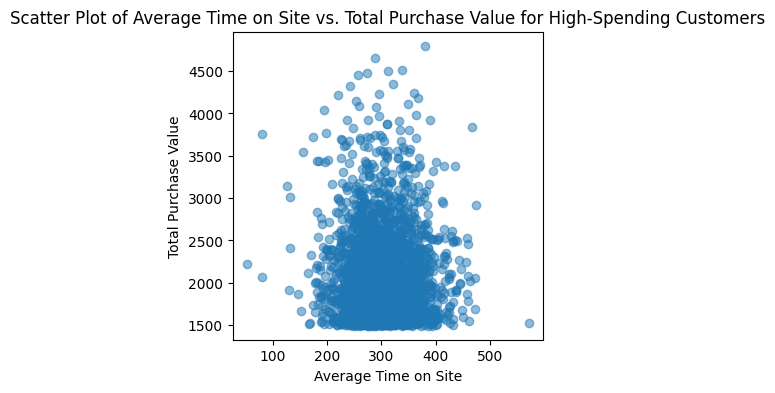

In [69]:
plt.figure(figsize=(4, 4))
plt.scatter(high_spend_df["avg_time_on_site"], high_spend_df["total_purchase_value"], alpha=0.5)
plt.xlabel("Average Time on Site")
plt.ylabel("Total Purchase Value")
plt.title("Scatter Plot of Average Time on Site vs. Total Purchase Value for High-Spending Customers")
plt.show()

There is no corelation between high spending customers and their session time on the site. With high p-value and zero correlation coefficient an association cannot be proved.

C2. Find a relationship (difference or correlation) that you believe is meaningful for business strategy.

Explain why.

I would like to explore this claim - Do refunded and non-refunded purchases differ in value?

H₀: The average purchase value is the same for refunded and non-refunded transactions.

H₁: The average purchase values differ.

In [93]:
transactions.head()

,transaction_id,customer_id,product_category,purchase_value,discount_used,purchase_date,is_refunded,refund_date,refund_reason
0,1,8141,home,380.95,0,2023-09-05,0,NaN,NaN
1,2,1297,fashion,67.08,0,2019-08-07,0,NaN,NaN
2,3,7930,toys,43.37,1,2020-02-07,1,1.581898e+18,late_delivery
3,4,2426,electronics,1191.45,0,2020-10-02,0,NaN,NaN
4,5,6614,fashion,112.21,0,2023-09-15,0,NaN,NaN


In [94]:
from scipy.stats import ttest_ind

#extracting refund transactions and non-refund transactions purchase values

refunded_purchases = transactions.loc[transactions['is_refunded'] == 1, 'purchase_value'].dropna()

non_refunded_purchases = transactions.loc[transactions['is_refunded'] == 0, 'purchase_value'].dropna()


#calculating means and p-value using t-test
refunded_mean = refunded_purchases.mean()
non_refunded_mean = non_refunded_purchases.mean()
result = ttest_ind(refunded_purchases,non_refunded_purchases,equal_var=False)

#printing the means, t-statistic and p-value
print("Refunded mean:", round(refunded_mean, 2))
print("Non-refunded mean:", round(non_refunded_mean, 2))
print("t-statistic:", round(result.statistic, 3))
print("p-value:", round(result.pvalue, 4))

Refunded mean: 235.73
Non-refunded mean: 234.8
t-statistic: 0.211
p-value: 0.8329


Because the p-value is much higher than 0.05, there isn’t enough evidence to conclude that average purchase value differs between refunded and non-refunded transactions. This compares the original recorded purchase values; it does not measure the financial impact of refunds themselves.

This test is relevant because a business may want to know whether higher-value purchases are more likely to be refunded. If they were, the company might review refund exposure on expensive orders; if not, it may need to look at other factors, such as product category or refund reason.

In this data, the average recorded purchase value was very similar for refunded and non-refunded transactions (235.73 vs. 234.80), and the difference was not statistically significant (p = 0.833). So the result does not support the idea that refunded purchases are higher- or lower-value on average.

That is still useful as a finding: purchase value alone may not be a helpful way to distinguish refunded transactions in this dataset. It doesn’t explain why refunds happen or measure the financial impact of refunds; it points to other variables as better candidates to investigate.

c3. Identify a statistically significant result that may not be practically meaningful.

Explain why statistical significance ≠ business importance.

I would like to explore the marketing campaigns and their relation to conversion for this challenge. 

Campaign click status and it's relation with conversion

In [70]:
campaigns.head()

,customer_id,campaign_id,touchpoint_id,touchpoint_date,clicked,converted
0,1,183,1,2019-07-12,1,0
1,2,548,2,2022-02-27,0,0
2,3,37,3,2024-05-11,1,1
3,4,14,4,2022-06-15,1,1
4,5,635,5,2024-07-08,1,1


In [84]:
# Performing a chi-square test to see if there's a significant association between click status and conversion
from scipy.stats import chi2_contingency

# Create a contingency table for campaign type and conversion
table = pd.crosstab(campaigns['clicked'], campaigns['converted'])
chi2, p_value, dof, expected = chi2_contingency(table)

print(table)
print(f"Chi-square statistic: {chi2:.3f}")  
print(f"p-value: {p_value:.6f}")

converted     0     1
clicked              
0          2946     0
1          2907  4147
Chi-square statistic: 2956.632
p-value: 0.000000


In [85]:
# Count converted (1) and not converted (0) for each click status
table = pd.crosstab(campaigns['clicked'], campaigns['converted'])

# Calculate conversion rate within each click group
conversion_rate = table[1] / table.sum(axis=1)

print(table)
print(f"Clicked: {table.loc[1, 1]:,} of {table.loc[1].sum():,} converted "
      f"({conversion_rate.loc[1]:.1%})")
print(f"Did not click: {table.loc[0, 1]:,} of {table.loc[0].sum():,} converted "
      f"({conversion_rate.loc[0]:.1%})")


converted     0     1
clicked              
0          2946     0
1          2907  4147
Clicked: 4,147 of 7,054 converted (58.8%)
Did not click: 0 of 2,946 converted (0.0%)


In [91]:
from scipy.stats import ttest_ind

converted_time = sessions.loc[sessions['converted'] == 1, 'time_on_site'].dropna()

not_converted_time = sessions.loc[sessions['converted'] == 0, 'time_on_site'].dropna()

result = ttest_ind(
    converted_time,
    not_converted_time,
    equal_var=False
)

difference = converted_time.mean() - not_converted_time.mean()

print(f"Converted sessions: {len(converted_time):,}")
print(f"Average time: {converted_time.mean():.2f} seconds")
print(f"Non-converted sessions: {len(not_converted_time):,}")
print(f"Average time: {not_converted_time.mean():.2f} seconds")
print(f"Difference: {difference:.2f} seconds")
print(f"p-value: {result.pvalue:.3e}")


Converted sessions: 9,179
Average time: 311.19 seconds
Non-converted sessions: 60,921
Average time: 299.24 seconds
Difference: 11.96 seconds
p-value: 2.163e-19


**Campaign clicks and conversion:** In the campaign touchpoint data, 4,147 of 7,054 clicked records converted (58.8%), compared with 0 of 2,946 records that did not click. This is a strong observed difference, but it may reflect how campaign conversions are recorded or attributed. It does not by itself prove that clicking caused conversion.

**Session time and conversion:** Converted sessions averaged about *12 seconds longer* on site than non-converted sessions. The difference was statistically significant, but the size is small; whether 12 seconds matters operationally depends on the business context. This is an association, not evidence that longer sessions cause conversion.


Hence, this analysis shows a statistical significance but not necessarily business importance. We need to understand how the converted is defined and recorded in these tables, since the non-click group has zero recorded conversions to make any actionable comment.